# GEOM7001: Fire extent and severity mapping
## Green Wattle Creek subset, 2019-2020 Black Summer
### Sentinel-2 ARD (DEA) compared with NSW FESM

**Author:** S49936760 Benjamin Baran, University of Queensland, GEOM7001

**Research question.** To what extent can dNBR, RdNBR and RBR derived from multi-temporal Sentinel-2 imagery accurately discriminate fire severity classes within a subset of the Green Wattle Creek fire, and how does the performance of these single-index approaches compare with the independent NSW FESM product?

**Notebook purpose.** Reproducible DEA Sandbox workflow: data load and QA, index calculation, threshold classification, accuracy assessment against NSW FESM, and a Random Forest comparison.

**Study extent.** 0.022° buffer around 34.004°S, 150.543°E (Werombi / Green Wattle Creek). This extent is fixed for all subsequent analysis.

In [1]:
# GEOM7001 Green Wattle Creek fire severity - Section 1: Environment
# All analysis uses DEA Analysis Ready Data (nbart surface reflectance).

import datacube
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import xarray as xr
import sys

from dea_tools.datahandling import load_ard
from dea_tools.plotting import rgb, display_map
from dea_tools.bandindices import calculate_indices

# Reproducible plot defaults for later figure exports
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.bbox"] = "tight"

dc = datacube.Datacube(app="GEOM7001_GWC_fire_severity")
print("Datacube connection: OK")

Datacube connection: OK


## 1. Study extent

The analysis is restricted to a compact ~25km² subset of the Green Wattle Creek fire. A fixed geographic extent is defined here and reused for every load, index and accuracy step so that all outputs remain spatially consistent.

- Centroid: 34.004°S, 150.543°E
- Buffer: 0.022° (~2.4 km) latitude and longitude
- CRS for analysis: EPSG:3577 (Australian Albers), 10m pixels

In [2]:
# Fixed study extent. Do not change these values.
LAT_CENTRE = -34.004
LON_CENTRE = 150.543
BUFFER_DEG = 0.022

lat_range = (LAT_CENTRE - BUFFER_DEG, LAT_CENTRE + BUFFER_DEG)
lon_range = (LON_CENTRE - BUFFER_DEG, LON_CENTRE + BUFFER_DEG)

print(f"Latitude range: {lat_range}")
print(f"Longitude range: {lon_range}")

# Interactive location check
display_map(x=lon_range, y=lat_range)

Latitude range: (-34.025999999999996, -33.982)
Longitude range: (150.52100000000002, 150.565)


## 2. Sentinel-2 ARD load and QA

DEA Collection 3 Sentinel-2 ARD is already geometrically corrected and converted to nadir BRDF adjusted surface reflectance (`nbart_*`). Tasks in this section are:

1. Restrict to the study extent and required bands.
2. Apply cloud/shadow/saturation masking via `load_ard`.
3. Keep only images with a high proportion of good pixels (`min_gooddata`).
4. Inspect dates visually before compositing.

**Bands.** NBR uses NIR (B8, `nbart_nir_1`, 10m) and SWIR2 (B12, `nbart_swir_2`, 20m, resampled to 10m by the load). True-colour QA used B2, B3 and B4.

**Temporal scope.**
- Pre-fire baseline: 01 Oct 2019 - 30 Nov 2019 (before Green Wattle Creek ignition on 05 Dec 2019)
- Post-fire: 01-31 Jan 2020. Dec 2019 is avoided at first pass because of smoke.

If `min_gooddata=0.80` returns no observations, lower it incrementally (0.70, 0.60, 0.50...) rather than changing extent.

In [3]:
# Load parameters

query = dict(
    x= lon_range,
    y= lat_range,
    measurements = [
        "nbart_blue",     # B2: True-colour (QA)
        "nbart_green",    # B3: True-colour (QA)
        "nbart_red",      # B4: True-colour (QA)
        "nbart_nir_1",    # B8: NBR numerator, 10m)
        "nbart_swir_2",   # B12: NBR denominator, native 20m
    ],
    output_crs = "EPSG:3577",
    resolution = (-10, 10),
    group_by = "solar_day",
    skip_broken_datasets = True,
)

# Sentinel-2A/2B cover 2019-2020. Sentinel-2C not relevant (launched 05 Sep 2024).
S2_PRODUCTS = ["ga_s2am_ard_3", "ga_s2bm_ard_3"]

# Relax threshold if load is empty or unsuitable
MIN_GOODDATA = 0.80

In [4]:
# Pre-fire stack: Oct-Nov 2019
# A median composite is built later to address residual cloud and short-term phenology.

pre = load_ard(
    dc = dc,
    products = S2_PRODUCTS,
    time = ("2019-10-01", "2019-11-30"),
    min_gooddata = MIN_GOODDATA,
    **query,
)

print("PRE-FIRE")
print(pre)
print("Dates:", [np.datetime_as_string(t, unit="D") for t in pre.time.values])
print("Good pixel load threshold:", MIN_GOODDATA)

Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
Counting good quality pixels for each time step using fmask
Filtering to 7 out of 10 time steps with at least 80.0% good quality pixels
Applying fmask pixel quality/cloud mask
Loading 7 time steps
PRE-FIRE
<xarray.Dataset> Size: 36MB
Dimensions:       (time: 7, y: 545, x: 472)
Coordinates:
  * time          (time) datetime64[ns] 56B 2019-10-17T00:06:13.012172 ... 20...
  * y             (y) float64 4kB -3.832e+06 -3.832e+06 ... -3.837e+06
  * x             (x) float64 4kB 1.696e+06 1.696e+06 ... 1.701e+06 1.701e+06
    spatial_ref   int32 4B 3577
Data variables:
    nbart_blue    (time, y, x) float32 7MB 239.0 170.0 195.0 ... nan nan nan
    nbart_green   (time, y, x) float32 7MB 339.0 223.0 304.0 ... nan nan nan
    nbart_red     (time, y, x) float32 7MB 240.0 175.0 217.0 ... nan nan nan
    nbart_nir_1   (time, y, x) float32 7MB 1.859e+03 1.281e+03 ... nan nan
    nbart_swir_2  (time, y, x) float32 7MB 1.141e+03 1.088e+03 ... nan n

In [5]:
# Post-fire stack: Jan 2020
# Prefer a single clear image over a median if several dates survive masking. A median of mixed dates can blur active fire and smoke.

post = load_ard(
    dc = dc,
    products = S2_PRODUCTS,
    time = ("2020-01-01", "2020-01-31"),
    min_gooddata = MIN_GOODDATA,
    **query,
)

print("POST-FIRE")
print(post)
print("Dates:", [np.datetime_as_string(t, unit="D") for t in post.time.values])

Finding datasets
    ga_s2am_ard_3
    ga_s2bm_ard_3
Counting good quality pixels for each time step using fmask
Filtering to 5 out of 6 time steps with at least 80.0% good quality pixels
Applying fmask pixel quality/cloud mask
Loading 5 time steps
POST-FIRE
<xarray.Dataset> Size: 26MB
Dimensions:       (time: 5, y: 545, x: 472)
Coordinates:
  * time          (time) datetime64[ns] 40B 2020-01-05T00:06:06.714573 ... 20...
  * y             (y) float64 4kB -3.832e+06 -3.832e+06 ... -3.837e+06
  * x             (x) float64 4kB 1.696e+06 1.696e+06 ... 1.701e+06 1.701e+06
    spatial_ref   int32 4B 3577
Data variables:
    nbart_blue    (time, y, x) float32 5MB 673.0 636.0 696.0 ... 583.0 585.0
    nbart_green   (time, y, x) float32 5MB 697.0 659.0 702.0 ... 611.0 639.0
    nbart_red     (time, y, x) float32 5MB 622.0 607.0 630.0 ... 704.0 716.0
    nbart_nir_1   (time, y, x) float32 5MB 1.6e+03 1.337e+03 ... 1.204e+03
    nbart_swir_2  (time, y, x) float32 5MB 1.187e+03 1.204e+03 ... 2.03e

## 3. Visual QA

Check the following:

1. Extent covers the intended Green Wattle Creek / Werombi area.
2. Pre-fire images should be drought-stressed but unburnt.
3. Post-fire images show a burn mosaic and are not dominated by cloud, smoke or shadow.
4. Band ranges are surface reflectance (0-10,000 scaled / 0-1 unscaled).

Pre-fire images: 7


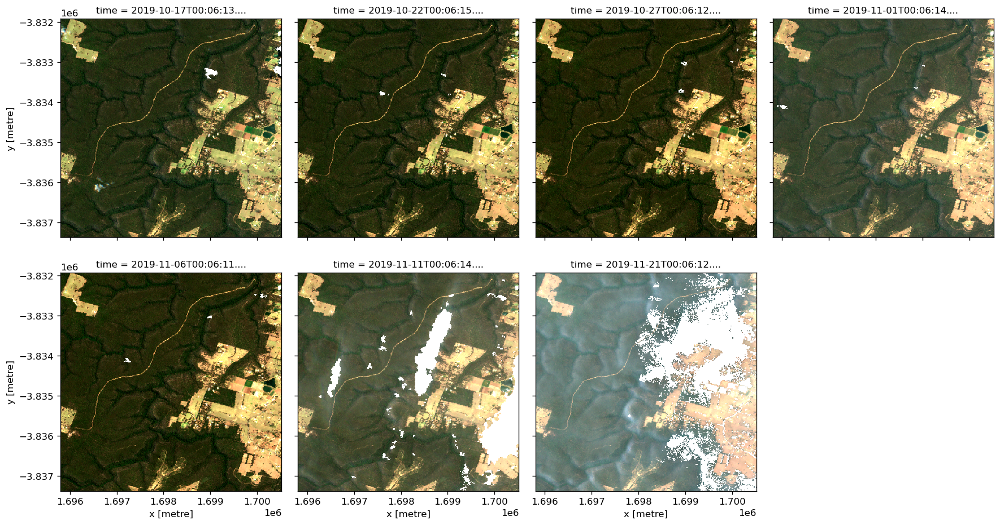

In [6]:
# True-colour inspection: Pre-fire

print("Pre-fire images:", pre.sizes.get("time", 1))
rgb(pre, bands=["nbart_red", "nbart_green", "nbart_blue"], col="time", size=4)

Post-fire images: 5


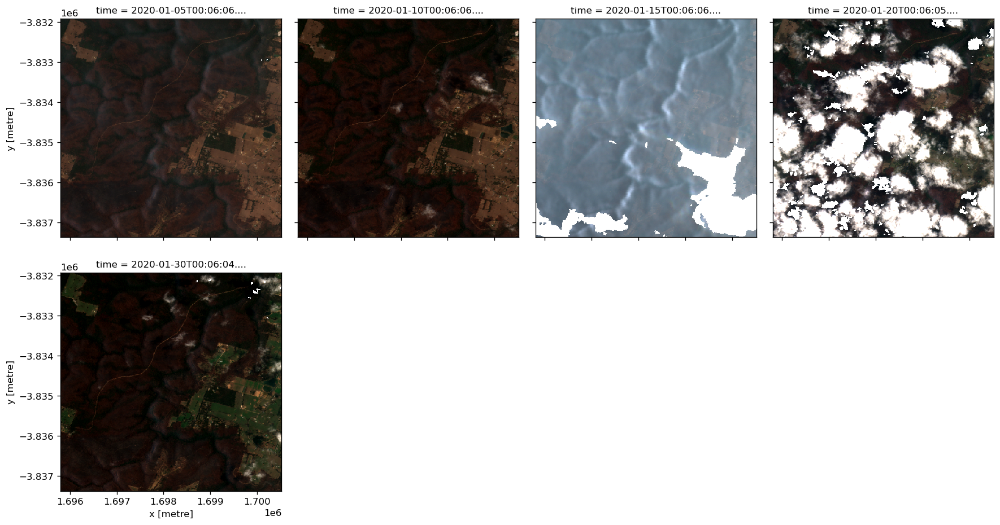

In [7]:
# True-colour inspection: Post-fire

print("Post-fire images:", post.sizes.get("time", 1))
rgb(post, bands=["nbart_red", "nbart_green", "nbart_blue"], col="time", size=4)

## 4. Image selection and reference images

Visual QA of all scenes passing `min_gooddata=0.80` produced the following decision:

**Pre-fire (median composite).** Kept 2019-10-17, 2019-10-22, 2019-10-27, 2019-11-01 and 2019-11-06. Discarded 2019-11-11 and 2019-11-21. A median of the five clear dates is used as the pre-fire baseline.

**Post-fire (single date).** 2020-01-10 is used as the post-fire reference. 2020-01-15 and 2020-01-20 are cloud contaminated. 2020-01-30 is clear but shows some vegetation green-up (post-fire recovery). 2020-01-05 remains available if required for later sensitivity check.

These two reference images will be inputs to the spectral indices.

In [8]:
# Image selection - confirmed after visual QA

PRE_KEEP = [
    "2019-10-17",
    "2019-10-22",
    "2019-10-27",
    "2019-11-01",
    "2019-11-06",
]

POST_DATE = "2020-01-10"

# Select by calendar date
pre_dates = pre.time.dt.strftime("%Y-%m-%d")
pre_clear = pre.sel(time=pre_dates.isin(PRE_KEEP))

post_ref = post.sel(time=POST_DATE, method="nearest")
# Note: sel() on a single date can leave a single dimensional time axis, therefore remove it if it occurs
if "time" in post_ref.dims:
    post_ref = post_ref.squeeze("time", drop=True)

# Median baseline: ignore NaNs from cloud masks in individual dates
pre_ref = pre_clear.median(dim="time", keep_attrs=True)

print("Pre-fire dates in composite:", list(pre_clear.time.dt.strftime("%Y-%m-%d").values))
print("Post-fire date:", np.datetime_as_string(post_ref.time.values, unit="D")
      if "time" in post_ref.coords else POST_DATE)
print("Pre-fire shape:", dict(pre_ref.sizes))
print("Post-fire shape:", dict(post_ref.sizes))

# Approximate analysis area from valid pixels (10m grid)
valid=pre_ref["nbart_nir_1"].notnull() & post_ref["nbart_nir_1"].notnull()
n_valid = int(valid.sum())
print(f"Valid overlapping pixels: {n_valid:,}")
print(f"Approximate valid area: {n_valid * 10 * 10 / 1000000:.2f} km²")

Pre-fire dates in composite: ['2019-10-17', '2019-10-22', '2019-10-27', '2019-11-01', '2019-11-06']
Post-fire date: 2020-01-10
Pre-fire shape: {'y': 545, 'x': 472}
Post-fire shape: {'y': 545, 'x': 472}
Valid overlapping pixels: 257,240
Approximate valid area: 25.72 km²


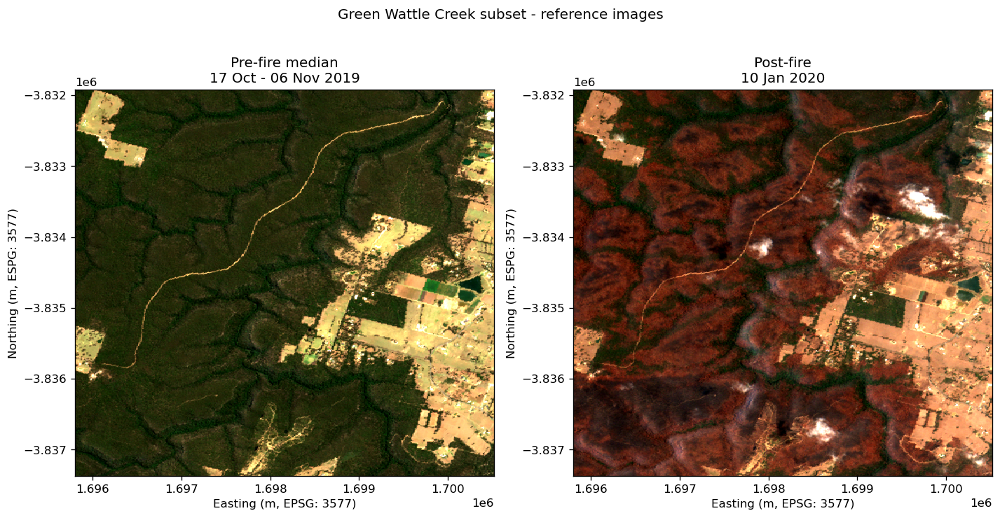

In [9]:
# Create a report-ready QA pair for the two reference images

fig, axes = plt.subplots(1, 2, figsize=(12,6))

rgb(pre_ref, bands=["nbart_red", "nbart_green", "nbart_blue"], ax=axes[0])
axes[0].set_title("Pre-fire median\n17 Oct - 06 Nov 2019")

rgb(post_ref, bands=["nbart_red", "nbart_green", "nbart_blue"], ax=axes[1])
axes[1].set_title("Post-fire\n10 Jan 2020")

for ax in axes:
    ax.set_xlabel("Easting (m, EPSG: 3577)")
    ax.set_ylabel("Northing (m, ESPG: 3577)")

fig.suptitle("Green Wattle Creek subset - reference images", y=1.02)
plt.tight_layout()
plt.show()

## 5. Spectral indices

NBR uses NIR (`nbart_nir_1`, B8) and SWIR2 (`nbart_swir_2`, B12):

$$
\mathrm{NBR} = \frac{\mathrm{NIR} - \mathrm{SWIR}}{\mathrm{NIR} + \mathrm{SWIR}}
$$

Both `nbart` bands are in the same scaled units, so the ratio is independent of the 0–10000 offset. NBR is left in the range −1 to +1.

$$
\mathrm{dNBR} = \mathrm{NBR}_{pre} - \mathrm{NBR}_{post}
$$

$$
\mathrm{RdNBR} = \frac{\mathrm{dNBR}}{\sqrt{|\mathrm{NBR}_{pre}|}}
$$

(Miller & Thode, 2007). A small offset is added inside the square root so pixels with
$\mathrm{NBR}_{pre} \approx 0$ do not explode.

$$
\mathrm{RBR} = \frac{\mathrm{dNBR}}{\mathrm{NBR}_{pre} + 1.001}
$$

(Parks et al., 2014). The 1.001 offset is the published constant.

Positive dNBR / RdNBR / RBR indicates a fire-like spectral change (NIR drop, SWIR rise).

In [10]:
# Spectral indices

# NBR is computed directly so the equation in the project report matches this code

def nbr(ds):
    nir = ds["nbart_nir_1"].astype("float32")
    swir = ds["nbart_swir_2"].astype("float32")
    return (nir - swir) / (nir + swir)

nbr_pre = nbr(pre_ref).rename("NBR_pre")
nbr_post = nbr(post_ref).rename("NBR_post")

dnbr = (nbr_pre - nbr_post).rename("dNBR")

# RdNBR (Relatiive change). The offset avoids any 'division by zero' due to bare ground, drought etc.
rdnbr = (dnbr / np.sqrt(np.abs(nbr_pre) + 0.000001)).rename("RdNBR")

# RBR: Parks et al (2014). Offset of +1.001.
rbr = (dnbr / (nbr_pre + 1.001)).rename("RBR")

# Keep one dataset for later classification and exports
indices = xr.merge([nbr_pre, nbr_post, dnbr, rdnbr, rbr])

print(indices)
print("\n Index ranges (valid pixels)")
for name in ["NBR_pre", "NBR_post", "dNBR", "RdNBR", "RBR"]:
    arr = indices[name]
    print(
        f"{name:8s}  min={float(arr.min()):7.3f}  "
        f"p2={float(arr.quantile(0.02)):7.3f}  "
        f"med={float(arr.median()):7.3f}  "
        f"p98={float(arr.quantile(0.98)):7.3f}  "
        f"max={float(arr.max()):7.3f}"
    )    

<xarray.Dataset> Size: 5MB
Dimensions:      (y: 545, x: 472)
Coordinates:
  * y            (y) float64 4kB -3.832e+06 -3.832e+06 ... -3.837e+06 -3.837e+06
  * x            (x) float64 4kB 1.696e+06 1.696e+06 ... 1.701e+06 1.701e+06
    spatial_ref  int32 4B 3577
    time         datetime64[ns] 8B 2020-01-10T00:06:06.164543
Data variables:
    NBR_pre      (y, x) float32 1MB 0.2548 0.09992 0.1759 ... 0.1451 0.1673
    NBR_post     (y, x) float32 1MB 0.1562 0.05108 0.1008 ... -0.2329 -0.2032
    dNBR         (y, x) float32 1MB 0.09852 0.04884 0.07506 ... 0.378 0.3705
    RdNBR        (y, x) float32 1MB 0.1952 0.1545 0.179 ... 1.02 0.9923 0.9058
    RBR          (y, x) float32 1MB 0.07846 0.04436 0.06378 ... 0.3298 0.3171

 Index ranges (valid pixels)
NBR_pre   min= -0.673  p2= -0.191  med=  0.177  p98=  0.312  max=  0.559
NBR_post  min= -0.469  p2= -0.315  med= -0.091  p98=  0.159  max=  0.442
dNBR      min= -0.761  p2=  0.021  med=  0.204  p98=  0.539  max=  0.795
RdNBR     min=-148.403

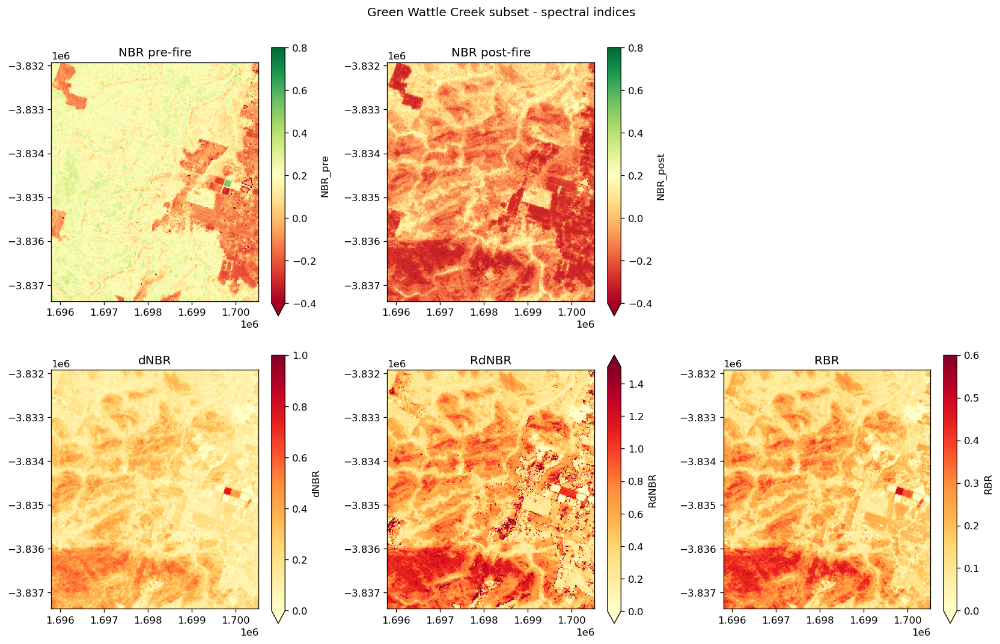

In [11]:
# Continuous surfaces.
fig, axes = plt.subplots(2, 3, figsize=(14,9))

# NBR: high = green vegetation, low = char / bare
nbr_pre.plot(ax=axes[0, 0], cmap="RdYlGn", vmin=-0.4, vmax=0.8, robust=False)
axes[0, 0].set_title("NBR pre-fire")

nbr_post.plot(ax=axes[0, 1], cmap="RdYlGn", vmin=-0.4, vmax=0.8, robust=False)
axes[0, 1].set_title("NBR post-fire")

# Hide unused top right
axes[0, 2].axis("off")

dnbr.plot(ax=axes[1, 0], cmap="YlOrRd", vmin=0, vmax=1.0)
axes[1, 0].set_title("dNBR")

rdnbr.plot(ax=axes[1, 1], cmap="YlOrRd", vmin=0, vmax=1.5)
axes[1, 1].set_title("RdNBR")

rbr.plot(ax=axes[1, 2], cmap="YlOrRd", vmin=0, vmax=0.6)
axes[1, 2].set_title("RBR")

for ax in axes.ravel():
    ax.set_aspect("equal")
    ax.set_xlabel("")
    ax.set_ylabel("")

fig.suptitle("Green Wattle Creek subset - spectral indices", y=1.0)
plt.tight_layout()
plt.show()

### Spectral Index QA notes

Pre-fire NBR is low for temperate forest (median 0.177; 98th percentile 0.312). That is consistent with late-2019 drought stress and the open dry-sclerophyll canopy of the Green Wattle Creek subset. Absolute dNBR is therefore expected to compress severity in the most sparsely vegetated pixels, which is the reason RdNBR and RBR are calculated alongside it (Miller & Thode, 2007; Parks et al., 2014).

Post-fire NBR falls to a median of −0.091 across the window, and dNBR is positive for almost all pixels (2nd percentile 0.021; median 0.204; 98th percentile 0.539). The spatial pattern follows the ridges visible in the 10 Jan 2020 true-colour image.

RdNBR shows extreme minimum and maximum values (approximately −148 to +305) where pre-fire NBR is near zero (bare paddocks, rock, drought and bare soil). These values are numerical artefacts of dividing by the square root of the absolute pre-fire NBR. Classification will use percentile based breaks and / or a pre-fire NBR magnitude mask rather than the raw RdNBR range. RBR does not show this instability and is the cleanest of the three continuous surfaces.

Display colour bars (`vmin` and `vmax`) are visualisation stretches only. They do not clip the stored arrays and are not class thresholds.

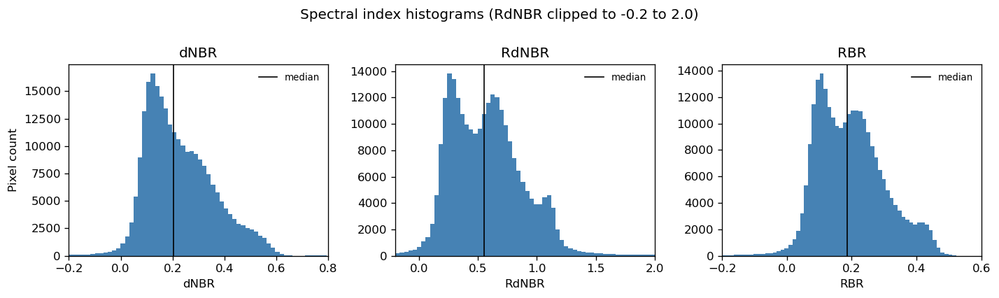

Pixels excluded from RdNBR plot: 3411


In [12]:
# Histogram distributions to help set severity thresholds

fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=False)

plot_limits = {
    "dNBR": (-0.2, 0.8),
    "RdNBR": (-0.2, 2.0),
    "RBR": (-0.2, 0.6),
}

for ax, name in zip(axes, ["dNBR", "RdNBR", "RBR"]):
    data = indices[name].values.ravel()
    data = data[np.isfinite(data)]
    low, high = plot_limits[name]
    data_plot = data[(data >= low) & (data <= high)]
    ax.hist(data_plot, bins=60, color="steelblue", edgecolor="none")
    ax.axvline(float(np.median(data[np.isfinite(data)])), color="black", lw=1, label="median")
    ax.set_xlim(low, high)
    ax.set_title(name)
    ax.set_xlabel(name)
    ax.legend(frameon=False, fontsize=8)

axes[0].set_ylabel("Pixel count")
fig.suptitle("Spectral index histograms (RdNBR clipped to -0.2 to 2.0)", y=1.0)
plt.tight_layout()
plt.show()

print("Pixels excluded from RdNBR plot:", int(np.sum(np.isfinite(indices["RdNBR"].values) & ((indices["RdNBR"].values < -0.2) | (indices["RdNBR"].values > 2.0)))))

## 6. Severity classification: literature thresholds

Each continuous index is defined into the five FESM classes (unburnt, low, moderate, high, extreme). The first run uses published (or equivalent) breaks so that later local refinement can be compared against a transparent baseline.

- **dNBR** breaks follow the USGS / Key and Benson sequence, divided by 1000 because NBR is stored in the range −1 to +1.
- **RdNBR** breaks follow Miller and Thode (2007), also converted from 1000-scaled units. An extra extreme class is added so the legend matches FESM. Pixels with |NBR pre| < 0.05 are masked for RdNBR only.
- **RBR** has no universal five-class table in Parks et al. (2014). Breaks are a scaled analogous of the dNBR sequence for this scene and will be revised after the FESM comparison.

These thresholds are a starting point only.

In [13]:
# Literature threshold classification (FESM class codes)
# 0 unburnt, 2 low, 3 moderate, 4 high, 5 extreme

DNBR_BREAKS = [0.10, 0.27, 0.44, 0.66]
RDNBR_BREAKS = [0.07, 0.32, 0.64, 1.00]
RBR_BREAKS = [0.09, 0.25, 0.40, 0.50]
CLASS_CODES = [0, 2, 3, 4, 5]
CLASS_NAMES = {
    0: "Unburnt",
    2: "Low",
    3: "Moderate",
    4: "High",
    5: "Extreme",
}

def classify_index(da, breaks, codes=CLASS_CODES):
    rules = [
        da < breaks[0],
        (da >= breaks[0]) & (da < breaks[1]),
        (da >= breaks[1]) & (da < breaks[2]),
        (da >= breaks[2]) & (da < breaks[3]),
        da >= breaks[3],
    ]
    out = xr.full_like(da, np.nan, dtype="float32")
    for rule, code in zip(rules, codes):
        out = out.where(~rule, code)
    return out.where(da.notnull()).rename(f"{da.name}_class")

# dNBR:
dnbr_class = classify_index(indices["dNBR"], DNBR_BREAKS)

# RdNBR: mask unstable low pre-fire NBR pixels before classifying
rdnbr_ok = np.abs(indices["NBR_pre"]) >= 0.05
rdnbr_class = classify_index(indices["RdNBR"].where(rdnbr_ok), RDNBR_BREAKS)

#RBR:
rbr_class = classify_index(indices["RBR"], RBR_BREAKS)

classes = xr.merge([dnbr_class, rdnbr_class, rbr_class])

# Get metrics from classifications
def class_counts(da, label):
    print(f"\n{label}")
    total = int(da.notnull().sum())
    for code in CLASS_CODES:
        n = int((da == code).sum())
        pct = 100 * n / total if total else 0
        print(f"  {code} {CLASS_NAMES[code]:10s}  {n:7d}  {pct:5.1f}%")
    if da.name and "RdNBR" in da.name:
        n_mask = int(da.isnull().sum() - int((~indices["dNBR"].notnull()).sum()))
        print(f"  masked (|NBR_pre| < 0.05): {int((~rdnbr_ok).sum()):d}")


class_counts(dnbr_class, "dNBR classes")
class_counts(rdnbr_class, "RdNBR classes")
class_counts(rbr_class, "RBR classes")


dNBR classes
  0 Unburnt       38015   14.8%
  2 Low          131461   51.1%
  3 Moderate      67379   26.2%
  4 High          20178    7.8%
  5 Extreme         207    0.1%

RdNBR classes
  0 Unburnt        4959    2.1%
  2 Low           56928   23.6%
  3 Moderate      88892   36.9%
  4 High          70271   29.2%
  5 Extreme       19967    8.3%
  masked (|NBR_pre| < 0.05): 16223

RBR classes
  0 Unburnt       37204   14.5%
  2 Low          147455   57.3%
  3 Moderate      60560   23.5%
  4 High          11942    4.6%
  5 Extreme          79    0.0%


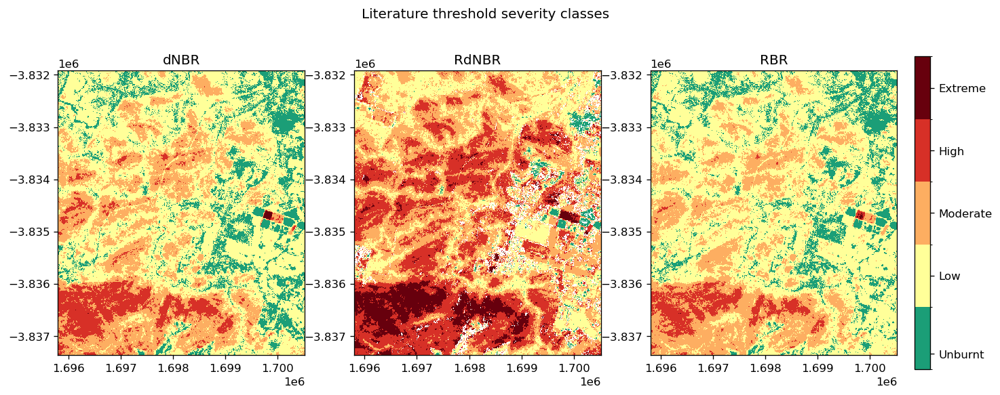

In [14]:
# Discrete colours so each FESM class has one legend colour. Do not use a continuous cmap (would imply a smooth scale).
from matplotlib.colors import ListedColormap, BoundaryNorm

# Order matches CLASS_CODES: unburnt, low, moderate, high, extreme
cmap = ListedColormap(["#1b9e77", "#ffff99", "#fdae61", "#d73027", "#67000d"])

# Bin edges sit between the class codes (0 / 2 / 3 / 4 / 5) so each code is symbolised with exactly one colour.
norm = BoundaryNorm([-0.5, 1.5, 2.5, 3.5, 4.5, 5.5], cmap.N)

fig, axes = plt.subplots(1, 3, figsize=(14, 5))

for ax, da, title in zip(axes, [dnbr_class, rdnbr_class, rbr_class], ["dNBR", "RdNBR", "RBR"]):
    im = da.plot(ax=ax, cmap=cmap, norm=norm, add_colorbar=False)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlabel("")
    ax.set_ylabel("")

# One shared legend for all three images
cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02, ticks=CLASS_CODES)
cbar.ax.set_yticklabels([CLASS_NAMES[c] for c in CLASS_CODES])
fig.suptitle("Literature threshold severity classes", y=1.0)
plt.show()

### Literature threshold results

On the USGS / Key and Benson dNBR sequence, 14.8% of the window is unburnt, 51.1% low, 26.2% moderate, 7.8% high and 0.1% extreme. RBR, using the scaled analogue of those breaks, is almost the same (14.5%, 57.3%, 23.5%, 4.6%, 0%).

RdNBR using Miller and Thode (2007) breaks, with |NBR pre| < 0.05 masked (16223 pixels), shifts the distribution up: 2.1% unburnt, 23.6% low, 36.9% moderate, 29.2% high, 8.3% extreme.

This split is expected. Pre-fire NBR is already low (median 0.177), so an absolute index underestimates canopy consumption and a relative index overestimates it on drought, bare and paddock pixels. Which map is closer to ecological severity is an empirical question for the FESM comparison, not something to fix by modifying breaks by visual review.

## 7. NSW FESM reference

NSW FESM 2019/2020 (FESMv3) is the independent fire severity product (DCCEEW and NSW RFS). The statewide mosaic was clipped in ArcGIS Pro to a padded area around the study extent, then uploaded as `data/fesm/fesm_2019_20_gwc_clip.tif`.

FESM classes: 0 unburnt, 1 reserved, 2 low, 3 moderate, 4 high, 5 extreme. NoData is 255 (outside a mapped fire). The clip is in GDA1994 NSW Lambert and is warped onto the Sentinel-2 Australian Albers 10m grid with nearest neighbour so class codes are preserved.

In [15]:
# Load the NSW FESM clip and snap it to the Sentinel-2 grid

from pathlib import Path
from rasterio.enums import Resampling
import rioxarray

FESM_PATH = Path("data/fesm/fesm_2019_20_gwc_clip.tif")
print("FESM file exists:", FESM_PATH.exists())

# Convert the 255 NoData cells into NaN
fesm_src = rioxarray.open_rasterio(FESM_PATH, masked=True).squeeze()
fesm_src = fesm_src.rename("FESM")

print("Source CRS:", fesm_src.rio.crs)
print("Source shape:", dict(fesm_src.sizes))
print("Source unique values:", np.unique(fesm_src.values[~np.isnan(fesm_src.values)]))

# Same grid as dNBR classes (EPSG:3577, 10 m) and nearest neighbour keeps integer class codes intact
fesm = fesm_src.rio.reproject_match(dnbr_class, resampling=Resampling.nearest)
fesm = fesm.where(dnbr_class.notnull())  # clip to valid Sentinel-2 pixels
fesm.rio.write_crs("EPSG:3577", inplace=True)

print("Aligned CRS:", fesm.rio.crs)
print("Aligned shape:", dict(fesm.sizes))
print("Aligned unique values:", np.unique(fesm.values[~np.isnan(fesm.values)]))

class_counts(fesm, "FESM classes (aligned)")

FESM file exists: True
Source CRS: EPSG:3308
Source shape: {'y': 595, 'x': 537}
Source unique values: [0. 2. 3. 4. 5.]
Aligned CRS: EPSG:3577
Aligned shape: {'y': 545, 'x': 472}
Aligned unique values: [0. 2. 3. 4. 5.]

FESM classes (aligned)
  0 Unburnt       56973   22.4%
  2 Low           38829   15.3%
  3 Moderate      55402   21.8%
  4 High          62639   24.6%
  5 Extreme       40344   15.9%


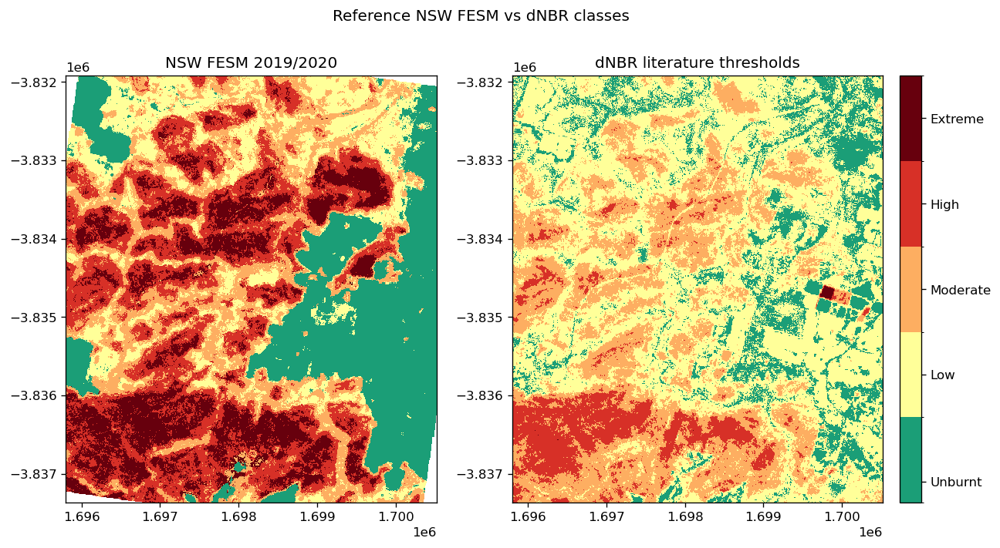

In [16]:
# Comparison: Official NSW FESM vs literature threshold dNBR

fig, axes = plt.subplots(1, 2, figsize=(12, 6))

for ax, da, title in zip( axes, [fesm, dnbr_class], ["NSW FESM 2019/2020", "dNBR literature thresholds"]):
    im = da.plot(ax=ax, cmap=cmap, norm=norm, add_colorbar=False)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlabel("")
    ax.set_ylabel("")

cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02, ticks=CLASS_CODES)
cbar.ax.set_yticklabels([CLASS_NAMES[c] for c in CLASS_CODES])
fig.suptitle("Reference NSW FESM vs dNBR classes", y=1.0)
plt.show()

## 8. Accuracy against NSW FESM

FESM is treated as the reference. Comparison is by pixels on the aligned 10m grid, using only pixels that have a class in both maps. Metrics:

- confusion matrix
- overall accuracy
- Cohen's kappa
- per-class user's accuracy (1 − commission) and producer's accuracy (1 − omission)

The literature threshold dNBR, RdNBR and RBR maps are all scored against the same NSW FESM raster so the three indices can be compared.

In [17]:
# Pixel accuracy of literature threshold maps against NSW FESM
from sklearn.metrics import confusion_matrix, cohen_kappa_score

CLASS_CODES = [0, 2, 3, 4, 5]
CLASS_LABELS = [CLASS_NAMES[c] for c in CLASS_CODES]


def score_against_fesm(pred, ref, title):
    # pred / ref are 2D DataArrays with FESM class codes
    mask = pred.notnull() & ref.notnull()
    y_true = ref.where(mask).values.ravel()
    y_pred = pred.where(mask).values.ravel()
    valid = np.isfinite(y_true) & np.isfinite(y_pred)
    y_true = y_true[valid].astype(int)
    y_pred = y_pred[valid].astype(int)

    cm = confusion_matrix(y_true, y_pred, labels=CLASS_CODES)
    oa = np.trace(cm) / cm.sum()
    kappa = cohen_kappa_score(y_true, y_pred, labels=CLASS_CODES)

    # Producer's accuracy = recall (columns are predicted, rows are reference)
    with np.errstate(divide="ignore", invalid="ignore"):
        pa = np.diag(cm) / cm.sum(axis=1)
        ua = np.diag(cm) / cm.sum(axis=0)

    print(f"\n{title}")
    print(f"  pixels: {cm.sum():,}   overall acc: {oa:.3f}   kappa: {kappa:.3f}")
    print("  confusion matrix (rows = FESM, cols = predicted)")
    header = "          " + "".join(f"{lab:>10s}" for lab in CLASS_LABELS)
    print(header)
    for lab, row in zip(CLASS_LABELS, cm):
        print(f"  {lab:8s}" + "".join(f"{n:10d}" for n in row))
    print("  producer's acc:",
          ", ".join(f"{lab}={p:.2f}" for lab, p in zip(CLASS_LABELS, pa)))
    print("  user's acc:    ",
          ", ".join(f"{lab}={u:.2f}" for lab, u in zip(CLASS_LABELS, ua)))
    return cm, oa, kappa


cm_dnbr, oa_dnbr, k_dnbr = score_against_fesm(dnbr_class, fesm, "dNBR literature thresholds vs FESM")
cm_rdnbr, oa_rdnbr, k_rdnbr = score_against_fesm(rdnbr_class, fesm, "RdNBR literature thresholds vs FESM")
cm_rbr, oa_rbr, k_rbr = score_against_fesm(rbr_class, fesm, "RBR literature thresholds vs FESM")


dNBR literature thresholds vs FESM
  pixels: 254,187   overall acc: 0.255   kappa: 0.082
  confusion matrix (rows = FESM, cols = predicted)
             Unburnt       Low  Moderate      High   Extreme
  Unburnt      20436     34921      1232       182       202
  Low          10812     27648       361         8         0
  Moderate      5188     39403     10570       241         0
  High           398     21778     34389      6073         1
  Extreme        438      6194     20271     13437         4
  producer's acc: Unburnt=0.36, Low=0.71, Moderate=0.19, High=0.10, Extreme=0.00
  user's acc:     Unburnt=0.55, Low=0.21, Moderate=0.16, High=0.30, Extreme=0.02

RdNBR literature thresholds vs FESM
  pixels: 238,236   overall acc: 0.470   kappa: 0.327
  confusion matrix (rows = FESM, cols = predicted)
             Unburnt       Low  Moderate      High   Extreme
  Unburnt       3822     17181     18015      6025      1065
  Low            471     25299     11731       376        13
  Mode

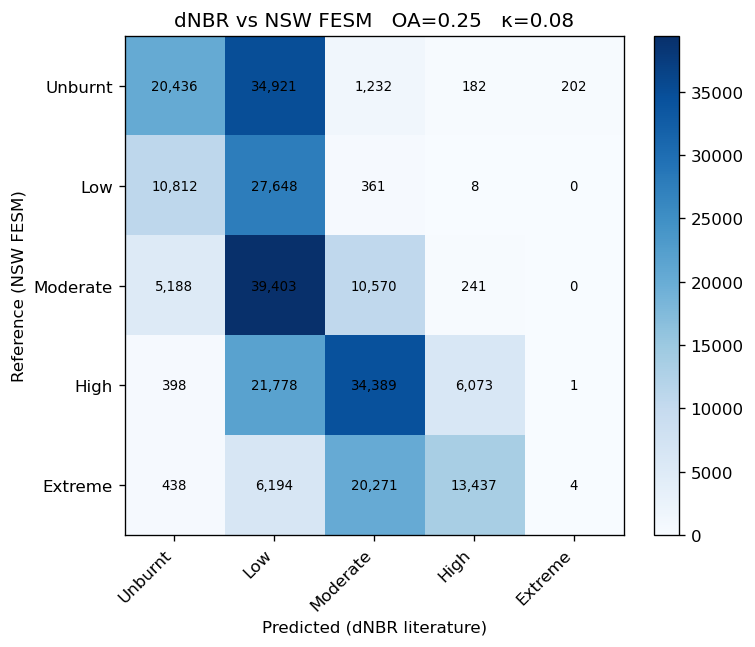

In [18]:
# Confusion matrix figure for the report (dNBR vs NSW FESM)

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm_dnbr, cmap="Blues")
ax.set_xticks(range(5))
ax.set_yticks(range(5))
ax.set_xticklabels(CLASS_LABELS, rotation=45, ha="right")
ax.set_yticklabels(CLASS_LABELS)
ax.set_xlabel("Predicted (dNBR literature)")
ax.set_ylabel("Reference (NSW FESM)")
ax.set_title(f"dNBR vs NSW FESM   OA={oa_dnbr:.2f}   κ={k_dnbr:.2f}")

for i in range(5):
    for j in range(5):
        ax.text(j, i, f"{cm_dnbr[i, j]:,}", ha="center", va="center", fontsize=8)

fig.colorbar(im, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

## 9. Index values by NSW FESM class

To set local specific thresholds, dNBR, RdNBR and RBR are grouped by the NSW FESM class of the same pixel. Breaks will be read from these distributions (median / interquartile gaps), not from the published USGS table.

This calibration uses the same pixels that were just scored, so the improved accuracy that follows is optimistic.

dNBR   FESM Unburnt   n= 56973  p25= 0.081  med= 0.126  p75= 0.176
dNBR   FESM Low       n= 38829  p25= 0.097  med= 0.121  p75= 0.150
dNBR   FESM Moderate  n= 55402  p25= 0.138  med= 0.188  p75= 0.252
dNBR   FESM High      n= 62639  p25= 0.246  med= 0.301  p75= 0.364
dNBR   FESM Extreme   n= 40344  p25= 0.304  med= 0.384  p75= 0.471
RdNBR  FESM Unburnt   n= 46108  p25= 0.209  med= 0.349  p75= 0.534
RdNBR  FESM Low       n= 37890  p25= 0.225  med= 0.276  p75= 0.343
RdNBR  FESM Moderate  n= 53309  p25= 0.326  med= 0.443  p75= 0.572
RdNBR  FESM High      n= 61794  p25= 0.595  med= 0.684  p75= 0.792
RdNBR  FESM Extreme   n= 39135  p25= 0.773  med= 0.920  p75= 1.072
RBR    FESM Unburnt   n= 56973  p25= 0.085  med= 0.134  p75= 0.191
RBR    FESM Low       n= 38829  p25= 0.082  med= 0.101  p75= 0.124
RBR    FESM Moderate  n= 55402  p25= 0.117  med= 0.159  p75= 0.209
RBR    FESM High      n= 62639  p25= 0.210  med= 0.250  p75= 0.296
RBR    FESM Extreme   n= 40344  p25= 0.263  med= 0.324  p75= 0

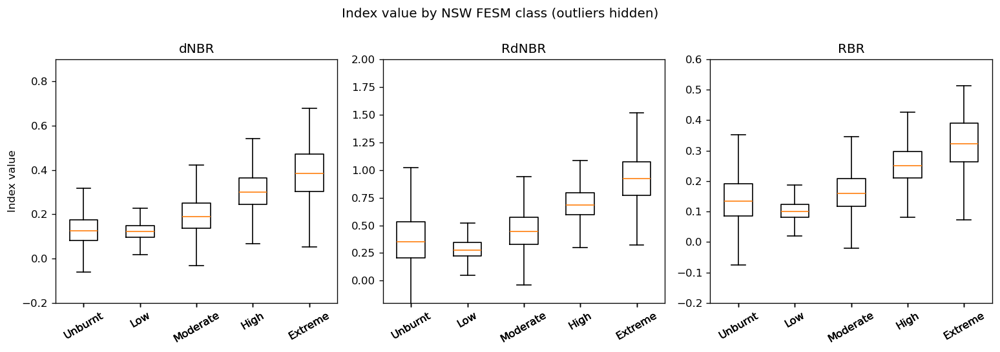

In [19]:
# Plots: index value on each NSW FESM class
# Note: RdNBR is clipped so artefact pixels do not influence the plot

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharex=True)

plot_items = [
    ("dNBR", indices["dNBR"], (-0.2, 0.9)),
    ("RdNBR", indices["RdNBR"].where(rdnbr_ok), (-0.2, 2.0)),
    ("RBR", indices["RBR"], (-0.2, 0.6)),
]

fesm_vals = fesm.values

for ax, (name, da, ylim) in zip(axes, plot_items):
    boxes = []
    for code in CLASS_CODES:
        data = da.values[fesm_vals == code]
        data = data[np.isfinite(data)]
        boxes.append(data)
        print(
            f"{name:5s}  FESM {CLASS_NAMES[code]:8s}  "
            f"n={len(data):6d}  p25={np.percentile(data, 25):6.3f}  "
            f"med={np.median(data):6.3f}  p75={np.percentile(data, 75):6.3f}"
        )
    ax.boxplot(boxes, tick_labels=[CLASS_NAMES[c] for c in CLASS_CODES], showfliers=False,)
    ax.set_title(name)
    ax.set_ylim(*ylim)
    ax.tick_params(axis="x", rotation=30)

axes[0].set_ylabel("Index value")
fig.suptitle("Index value by NSW FESM class (outliers hidden)", y=1.0)
plt.tight_layout()
plt.show()

## 10. Locally calibrated thresholds

New breaks are the mid-points between NSW FESM class medians, except Unburnt vs Low, which overlap and cannot be separated. The first break is placed just below that value so a residual unburnt class remains.

These breaks are fitted on the same pixels used for accuracy, so the new scores are optimistic. They are a demonstration of image-specific calibration, not an independent validation.

In [20]:
# Local breaks from FESM-class medians

DNBR_LOCAL = [0.11, 0.16, 0.24, 0.34]
RDNBR_LOCAL = [0.25, 0.36, 0.56, 0.80]
RBR_LOCAL = [0.09, 0.13, 0.21, 0.29]

dnbr_local = classify_index(indices["dNBR"], DNBR_LOCAL)
rdnbr_local = classify_index(indices["RdNBR"].where(rdnbr_ok), RDNBR_LOCAL)
rbr_local = classify_index(indices["RBR"], RBR_LOCAL)

class_counts(dnbr_local, "dNBR local classes")
class_counts(rdnbr_local, "RdNBR local classes")
class_counts(rbr_local, "RBR local classes")

cm_dnbr_l, oa_dnbr_l, k_dnbr_l = score_against_fesm(dnbr_local, fesm, "dNBR local vs FESM")
cm_rdnbr_l, oa_rdnbr_l, k_rdnbr_l = score_against_fesm(rdnbr_local, fesm, "RdNBR local vs FESM")
cm_rbr_l, oa_rbr_l, k_rbr_l = score_against_fesm(rbr_local, fesm, "RBR local vs FESM")

print("\nKappa comparison")
print(f"  dNBR   literature {k_dnbr:.3f}  local {k_dnbr_l:.3f}")
print(f"  RdNBR  literature {k_rdnbr:.3f}  local {k_rdnbr_l:.3f}")
print(f"  RBR    literature {k_rbr:.3f}  local {k_rbr_l:.3f}")


dNBR local classes
  0 Unburnt       47696   18.5%
  2 Low           47397   18.4%
  3 Moderate      56973   22.1%
  4 High          54232   21.1%
  5 Extreme       50942   19.8%

RdNBR local classes
  0 Unburnt       36610   15.2%
  2 Low           37727   15.7%
  3 Moderate      51737   21.5%
  4 High          67856   28.2%
  5 Extreme       47087   19.5%
  masked (|NBR_pre| < 0.05): 16223

RBR local classes
  0 Unburnt       37204   14.5%
  2 Low           43340   16.8%
  3 Moderate      68818   26.8%
  4 High          61387   23.9%
  5 Extreme       46491   18.1%

dNBR local vs FESM
  pixels: 254,187   overall acc: 0.445   kappa: 0.305
  confusion matrix (rows = FESM, cols = predicted)
             Unburnt       Low  Moderate      High   Extreme
  Unburnt      23757     14324     16002      2006       884
  Low          14820     16667      6489       786        67
  Moderate      7034     13076     19173     13240      2879
  High           541      1986     11747     27589     2

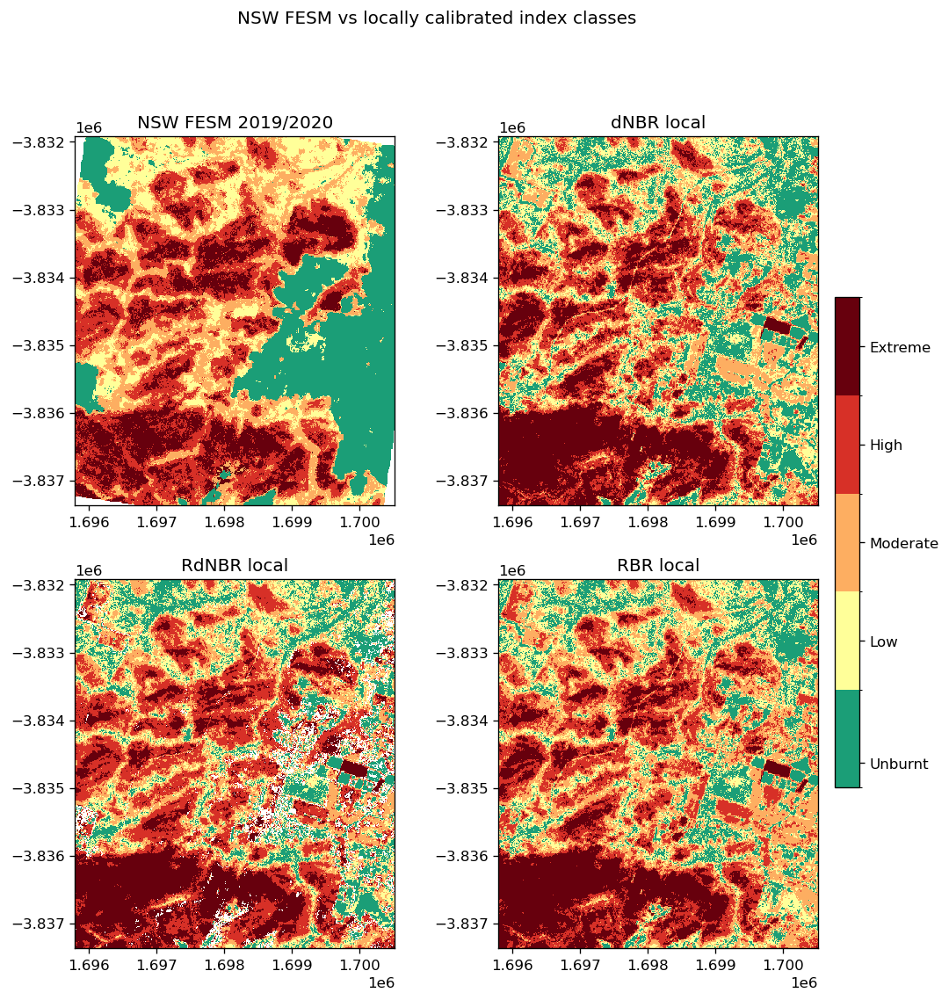

In [21]:
# NSW FESM vs locally calibrated dNBR, RdNBR and RBR
fig, axes = plt.subplots(2, 2, figsize=(10, 10))

panels = [
    (fesm, "NSW FESM 2019/2020"),
    (dnbr_local, "dNBR local"),
    (rdnbr_local, "RdNBR local"),
    (rbr_local, "RBR local"),
]

for ax, (da, title) in zip(axes.ravel(), panels):
    im = da.plot(ax=ax, cmap=cmap, norm=norm, add_colorbar=False)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlabel("")
    ax.set_ylabel("")

cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02, ticks=CLASS_CODES)
cbar.ax.set_yticklabels([CLASS_NAMES[c] for c in CLASS_CODES])
fig.suptitle("NSW FESM vs locally calibrated index classes", y=1.0)
plt.show()

### Local threshold results

Median based breaks raised dNBR kappa from 0.082 to 0.305 and RBR from 0.013 to 0.297. RdNBR was already the best literature map (kappa = 0.327) and only rose to 0.355. Extreme producer's accuracy on dNBR went from 0.00 to 0.64. Unburnt vs Low is still confused, and the eastern paddocks remains false extremes against NSW FESM. Scores are optimistic because the breaks were read from the same pixels used to score them.

## 11. Random Forest — design

NSW FESM is itself a Random Forest (RF) on Sentinel-2. Training an RF on the same sensor to predict FESM therefore asks a narrower question than the index maps: *how much of the official product can this image processing workflow reconstruct from bands plus burn indices as a light-weight surrogate to NSW FESM?*

This is still very useful. A single threshold cannot use the visible bands or pre-fire context, which is why the eastern paddock was labelled Extreme. An RF can use those features, but tt cannot create an independent field 'truth'.

Design choices:

- Features: pre and post-fire `nbart` bands (B2, B3, B4, B8, B12), NBR pre and post, dNBR, RdNBR, RBR. RdNBR is clipped to (−2, 3) so artefact pixels do not dominate the trees.
- Labels: aligned to NSW FESM (classes 0, 2, 3, 4, 5).
- Sample: stratified by NSW FESM class, 8 000 pixels per class or all pixels if a class is smaller, so Extreme is not dominated by Low.
- Split: 70% train / 30% test, stratified. The test pixels are not used to pick thresholds or to grow trees. A random split still ignores spatial autocorrelation and is noted as a limitation.

In [22]:
# Feature stack, stratified sample, train/test split

from sklearn.model_selection import train_test_split

# Clip RdNBR for use as a feature (classification mask is not applied)
rdnbr_feat = indices["RdNBR"].clip(-2, 3)

feat_ds = xr.Dataset(
    {
        "pre_blue": pre_ref["nbart_blue"],
        "pre_green": pre_ref["nbart_green"],
        "pre_red": pre_ref["nbart_red"],
        "pre_nir": pre_ref["nbart_nir_1"],
        "pre_swir": pre_ref["nbart_swir_2"],
        "post_blue": post_ref["nbart_blue"],
        "post_green": post_ref["nbart_green"],
        "post_red": post_ref["nbart_red"],
        "post_nir": post_ref["nbart_nir_1"],
        "post_swir": post_ref["nbart_swir_2"],
        "nbr_pre": indices["NBR_pre"],
        "nbr_post": indices["NBR_post"],
        "dnbr": indices["dNBR"],
        "rdnbr": rdnbr_feat,
        "rbr": indices["RBR"],
    }
)
FEATURE_NAMES = list(feat_ds.data_vars)

# Pixel is usable only if every feature and the NSW FESM label are finite
feat_ok = feat_ds.to_array().notnull().all("variable")
label_ok = fesm.notnull()
rf_ok = feat_ok & label_ok

print("RF valid pixels:", int(rf_ok.sum()))
print("Features:", FEATURE_NAMES)

# Flatten so that rows are pixels
X_all = np.column_stack([feat_ds[name].values[rf_ok.values] for name in FEATURE_NAMES])
y_all = fesm.values[rf_ok.values].astype(int)

print("X_all shape:", X_all.shape)
print("Label counts (all valid pixels):")
for code in CLASS_CODES:
    print(f"  {CLASS_NAMES[code]:10s} {int((y_all == code).sum()):7d}")

# Stratified cap so Extreme is not dominated by Unburnt/Low
RNG = np.random.default_rng(42)
MAX_PER_CLASS = 8000
sample_idx = []
for code in CLASS_CODES:
    idx = np.flatnonzero(y_all == code)
    take = min(MAX_PER_CLASS, idx.size)
    sample_idx.append(RNG.choice(idx, size=take, replace=False))
sample_idx = np.concatenate(sample_idx)

X_s = X_all[sample_idx]
y_s = y_all[sample_idx]

print("\nSampled pixels:", y_s.size)
for code in CLASS_CODES:
    print(f"  {CLASS_NAMES[code]:10s} {int((y_s == code).sum()):7d}")

X_train, X_test, y_train, y_test = train_test_split(X_s, y_s, test_size=0.30, random_state=42, stratify=y_s,)

print("\nTrain:", X_train.shape[0], " Test:", X_test.shape[0])
print("Train class counts:", {CLASS_NAMES[c]: int((y_train == c).sum()) for c in CLASS_CODES})
print("Test class counts: ", {CLASS_NAMES[c]: int((y_test == c).sum()) for c in CLASS_CODES})

RF valid pixels: 254187
Features: ['pre_blue', 'pre_green', 'pre_red', 'pre_nir', 'pre_swir', 'post_blue', 'post_green', 'post_red', 'post_nir', 'post_swir', 'nbr_pre', 'nbr_post', 'dnbr', 'rdnbr', 'rbr']
X_all shape: (254187, 15)
Label counts (all valid pixels):
  Unburnt      56973
  Low          38829
  Moderate     55402
  High         62639
  Extreme      40344

Sampled pixels: 40000
  Unburnt       8000
  Low           8000
  Moderate      8000
  High          8000
  Extreme       8000

Train: 28000  Test: 12000
Train class counts: {'Unburnt': 5600, 'Low': 5600, 'Moderate': 5600, 'High': 5600, 'Extreme': 5600}
Test class counts:  {'Unburnt': 2400, 'Low': 2400, 'Moderate': 2400, 'High': 2400, 'Extreme': 2400}


## 12. Random Forest — train and test score

200 trees, `min_samples_leaf=5` to limit one pixel rules, `n_jobs=-1`. Classes are already balanced in the sample, so no class-weight is applied.

Accuracy is reported on the 12 000 test pixels only. Feature importance is Gini importance across the 15 predictors.

In [23]:
# Train RF and score on the 30% test pixels

from sklearn.ensemble import RandomForestClassifier

rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=5,
    random_state=42,
    n_jobs=-1,
)
rf.fit(X_train, y_train)

y_hat = rf.predict(X_test)

cm_rf = confusion_matrix(y_test, y_hat, labels=CLASS_CODES)
oa_rf = np.trace(cm_rf) / cm_rf.sum()
k_rf = cohen_kappa_score(y_test, y_hat, labels=CLASS_CODES)

with np.errstate(divide="ignore", invalid="ignore"):
    pa_rf = np.diag(cm_rf) / cm_rf.sum(axis=1)
    ua_rf = np.diag(cm_rf) / cm_rf.sum(axis=0)

print("Random Forest vs NSW FESM (test)")
print(f"  pixels: {cm_rf.sum():,}   overall acc: {oa_rf:.3f}   kappa: {k_rf:.3f}")
print("  confusion matrix (rows = NSW FESM, cols = predicted)")
header = "        " + "".join(f"{lab:>10s}" for lab in CLASS_LABELS)
print(header)
for lab, row in zip(CLASS_LABELS, cm_rf):
    print(f"  {lab:8s}" + "".join(f"{n:10d}" for n in row))
print("  producer's acc:", ", ".join(f"{lab}={p:.2f}" for lab, p in zip(CLASS_LABELS, pa_rf)))
print("  user's acc:    ", ", ".join(f"{lab}={u:.2f}" for lab, u in zip(CLASS_LABELS, ua_rf)))

print("\nKappa:")
print(f"  dNBR literature {k_dnbr:.3f}")
print(f"  dNBR local      {k_dnbr_l:.3f}")
print(f"  RdNBR local     {k_rdnbr_l:.3f}")
print(f"  RF test         {k_rf:.3f}")

Random Forest vs NSW FESM (test)
  pixels: 12,000   overall acc: 0.715   kappa: 0.644
  confusion matrix (rows = NSW FESM, cols = predicted)
           Unburnt       Low  Moderate      High   Extreme
  Unburnt       2198       149        50         2         1
  Low             77      1843       441        34         5
  Moderate       104       596      1226       431        43
  High             5        35       346      1446       568
  Extreme         19         7        35       469      1870
  producer's acc: Unburnt=0.92, Low=0.77, Moderate=0.51, High=0.60, Extreme=0.78
  user's acc:     Unburnt=0.91, Low=0.70, Moderate=0.58, High=0.61, Extreme=0.75

Kappa:
  dNBR literature 0.082
  dNBR local      0.305
  RdNBR local     0.355
  RF test         0.644


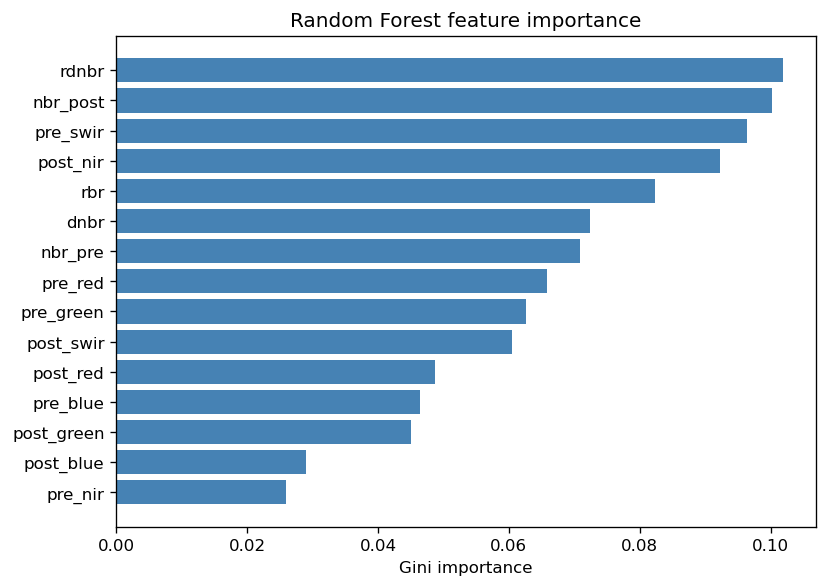

Top features:
  rdnbr        0.102
  nbr_post     0.100
  pre_swir     0.096
  post_nir     0.092
  rbr          0.082
  dnbr         0.072
  nbr_pre      0.071
  pre_red      0.066


In [24]:
# Determine which features the RF actually used
importances = rf.feature_importances_
order = np.argsort(importances)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(np.array(FEATURE_NAMES)[order], importances[order], color="steelblue")
ax.set_xlabel("Gini importance")
ax.set_title("Random Forest feature importance")
plt.tight_layout()
plt.show()

print("Top features:")
for name, val in sorted(zip(FEATURE_NAMES, importances), key=lambda t: -t[1])[:8]:
    print(f"  {name:12s} {val:.3f}")

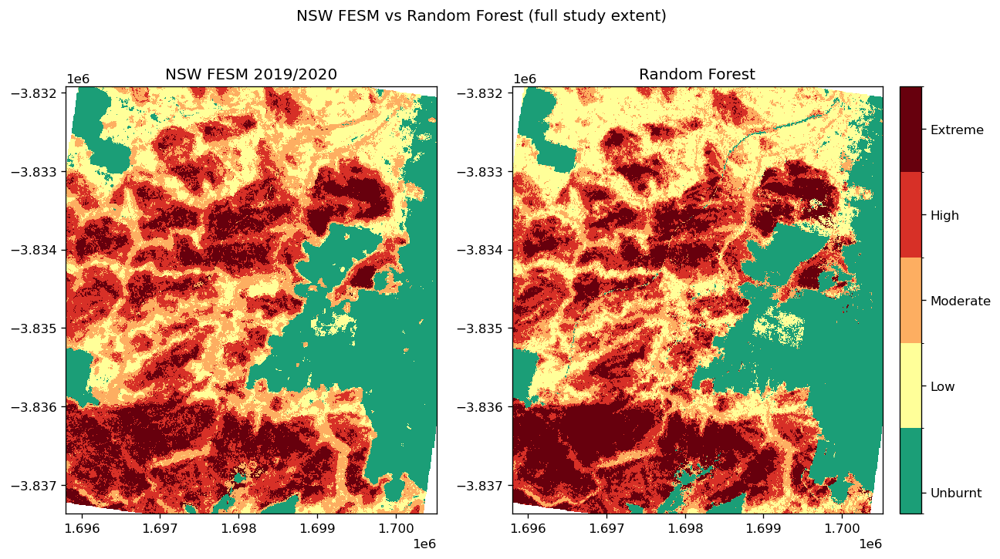


RF full-window classes
  0 Unburnt       56887   22.4%
  2 Low           48259   19.0%
  3 Moderate      46142   18.2%
  4 High          55742   21.9%
  5 Extreme       47157   18.6%


In [25]:
# Apply the fitted RF to every valid pixel

rf_map = xr.full_like(fesm, np.nan, dtype="float32").rename("RF")
rf_map.values[rf_ok.values] = rf.predict(X_all)
rf_map.rio.write_crs("EPSG:3577", inplace=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, da, title in zip(axes, [fesm, rf_map], ["NSW FESM 2019/2020", "Random Forest"]):
    im = da.plot(ax=ax, cmap=cmap, norm=norm, add_colorbar=False)
    ax.set_title(title)
    ax.set_aspect("equal")
    ax.set_xlabel("")
    ax.set_ylabel("")

cbar = fig.colorbar(im, ax=axes, fraction=0.03, pad=0.02, ticks=CLASS_CODES)
cbar.ax.set_yticklabels([CLASS_NAMES[c] for c in CLASS_CODES])
fig.suptitle("NSW FESM vs Random Forest (full study extent)", y=1.02)
plt.show()

class_counts(rf_map, "RF full-window classes")

### RF results

On the stratified test set, the RF reaches overall accuracy 0.715 and kappa 0.644, compared to 0.355 for the best locally calibrated index (RdNBR). Unburnt (PA 0.92, UA 0.91) and Extreme (PA 0.78, UA 0.75) are the strongest classes. Moderate remains the weakest (PA 0.51).

Gini importance is led by RdNBR, post-fire NBR, pre-fire SWIR and post-fire NIR. Visible bands contribute minimally. The model is using relative canopy change plus pre-fire dryness (drought).

The full study extent map is for illustration only. It includes training pixels, so it is not an independent accuracy surface. The comparison is also circular: NSW FESM itself is a RF on Sentinel-2. What this does show is that an image specific RF can reconstruct most of NSW FESM and could be considered a light-weight feasible surrogate in similar scene conditions.

## Notes

Study area: 25.72 km², 545 x 472 at 10 m, EPSG:3577
Pre-fire median: 2019-10-17, 10-22, 10-27, 11-01, 11-06
Post-fire: 2020-01-10
FESM clip: data/fesm/fesm_2019_20_gwc_clip.tif (EPSG:3308 → 3577, nearest)

NBR pre median 0.177; NBR post median −0.091

Literature kappa: dNBR 0.082, RdNBR 0.327, RBR 0.013
Local kappa:      dNBR 0.305, RdNBR 0.355, RBR 0.297
RF test:          OA 0.715, kappa 0.644 (12 000 pixels)

Local breaks
dNBR  [0.11, 0.16, 0.24, 0.34]
RdNBR [0.25, 0.36, 0.56, 0.80]
RBR   [0.09, 0.13, 0.21, 0.29]

RF: 200 trees, min_samples_leaf=5, 8000/class, 70/30 split
Top features: RdNBR, NBR_post, pre_SWIR, post_NIR